In [40]:
import numpy as np
import matplotlib.pylab as plt
from pydmd import HankelDMD
import pandas as pd

Here we fit to the first 1000 timepoints and predict the next 1000.

In [436]:
wf_dynamics = np.genfromtxt('gt_WF_dynamics.csv',delimiter=',')
RSE = lambda X,Y,Y_train: np.mean((Y-np.real(X))**2)/np.mean((Y-np.mean(Y_train))**2)
hdmd_full = HankelDMD(15,d=500,opt=True,tikhonov_regularization=1e-4)
hdmd_full.fit(wf_dynamics[:1000,1:].T)

def dynamics(dmd,timesteps,t0,dt):
    temp = np.repeat(dmd.eigs[:, None], timesteps.shape[0], axis=1)
    tpow = (timesteps - t0) / dt
    return np.power(temp, tpow) * dmd.amplitudes[:, None]

psi = hdmd_full.modes[-10:,:]*np.exp(-np.log(hdmd_full.eigs)*(hdmd_full.d-1))
forecast = psi@dynamics(hdmd_full,np.arange(hdmd_full.d,2000),0,1)

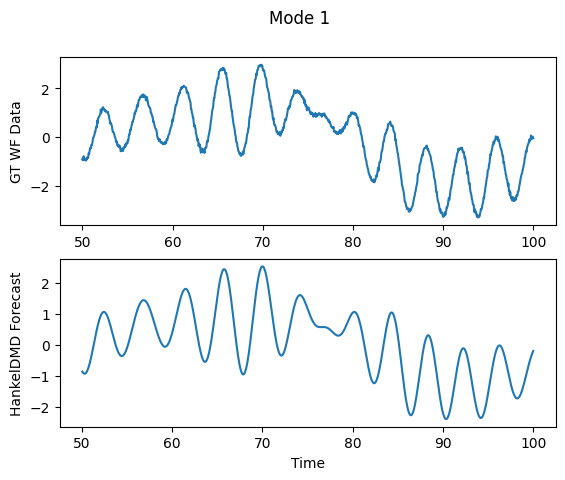

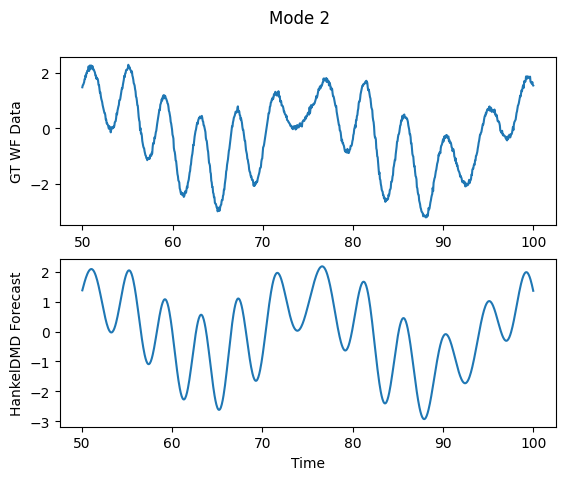

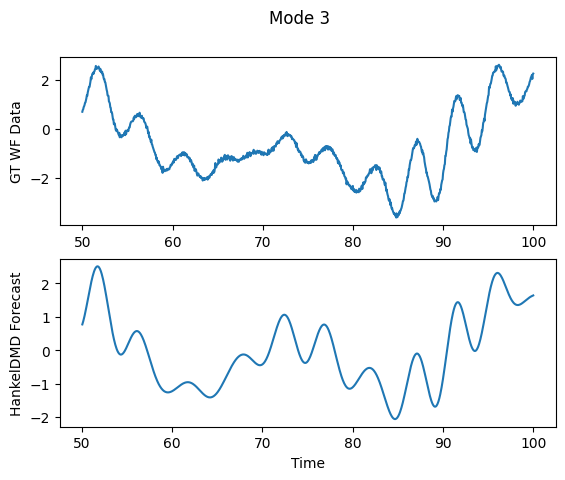

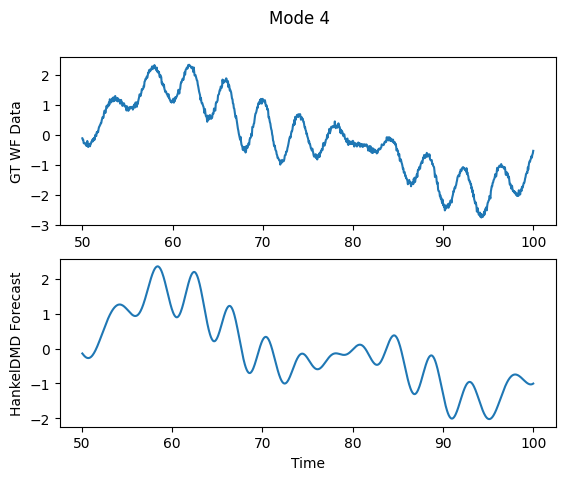

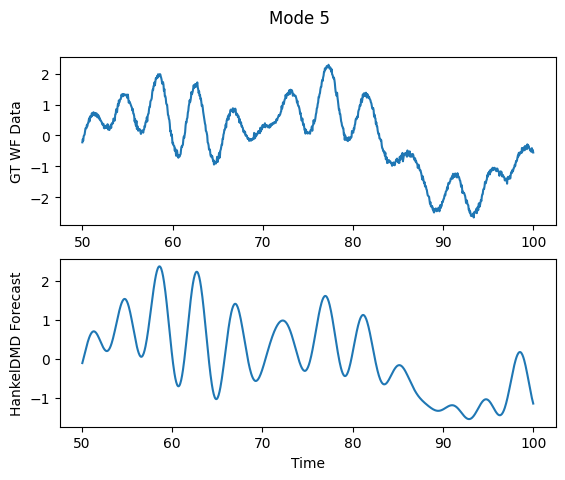

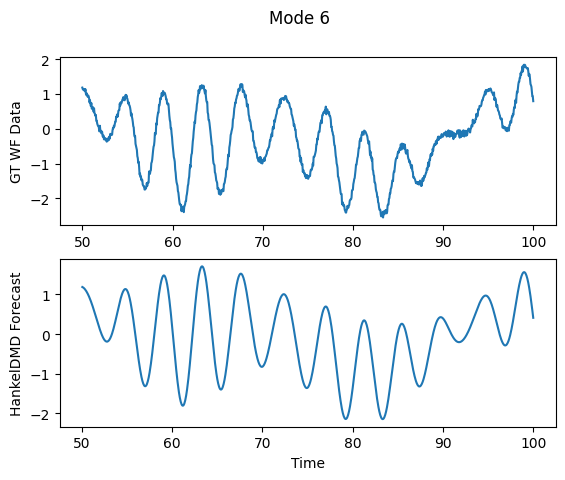

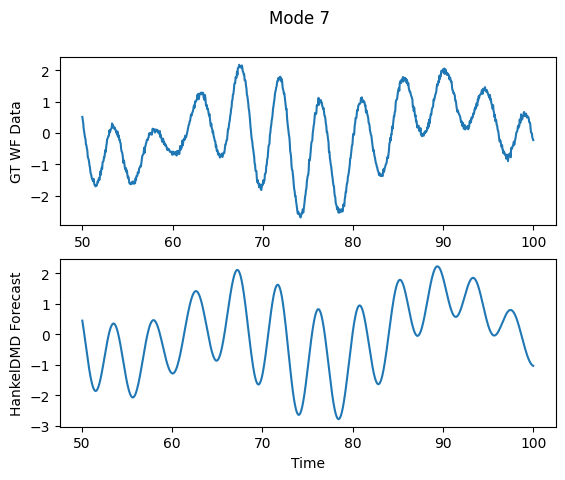

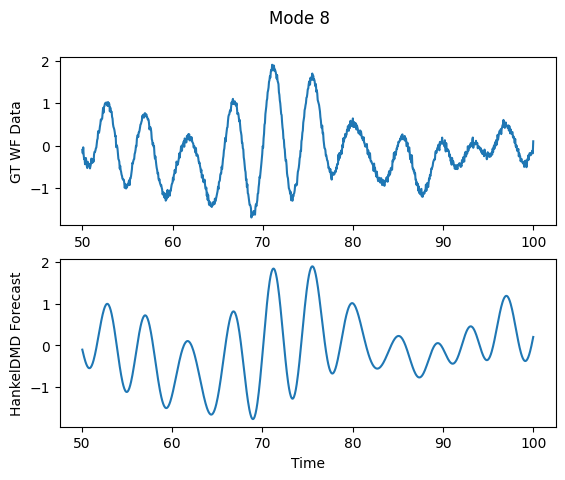

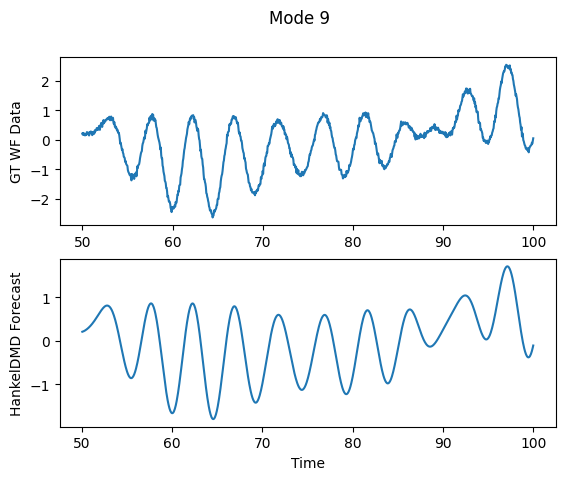

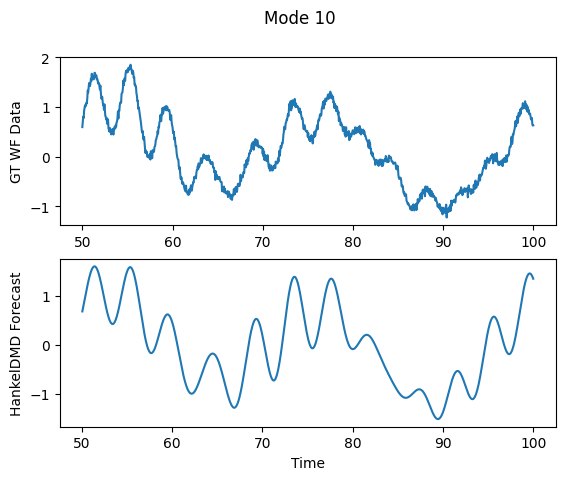

In [437]:
for i in range(10):
    fig,ax = plt.subplots(2)
    ax[0].plot(wf_dynamics[1000:,0],wf_dynamics[1000:,i+1])
    ax[0].set_ylabel("GT WF Data")
    ax[1].plot(wf_dynamics[1001:,0],forecast[i,500:])
    ax[1].set_ylabel("HankelDMD Forecast")
    ax[1].set_xlabel("Time")
    fig.suptitle("Mode " + str(i+1))

In [438]:
print("Overall RSE: " +str(RSE(forecast[:,500:1500],wf_dynamics[1001:2001,1:].T,wf_dynamics[:1000,1:].T)))

Overall RSE: 0.16772995582221095


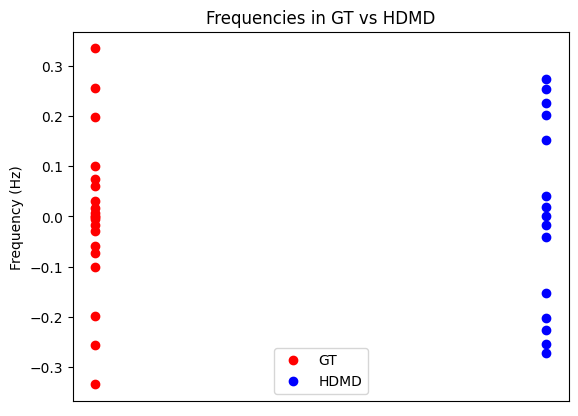

In [439]:
plt.plot(np.zeros(20),np.imag(np.diag(true_eigvals)),'ro',label="GT")
plt.plot(np.ones(15),np.imag(np.log(hdmd_full.eigs)/(2*np.pi*.05)),'bo',label="HDMD")
plt.xticks([])
plt.ylabel("Frequency (Hz)")
plt.title("Frequencies in GT vs HDMD")
plt.legend()